# STOR 320: Methods and Models of Data Science
## Spring 2026
## EDA Group 10 

In [1]:
# Run this cell first — shared imports for all group members
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_wine, load_digits
from sklearn.decomposition import PCA 
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR

# Load your merged dataset here
df = pd.read_csv("fixed_project_data.csv")

# Set a consistent style for all figures in this notebook
sns.set_theme(style="whitegrid")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4831 entries, 0 to 4830
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Track                   4831 non-null   str    
 1   Album Name              4831 non-null   str    
 2   Release Date            4831 non-null   str    
 3   All Time Rank           4831 non-null   int64  
 4   Track Score             4831 non-null   float64
 5   Spotify Streams         4744 non-null   float64
 6   Spotify Playlist Count  4785 non-null   float64
 7   Spotify Playlist Reach  4784 non-null   float64
 8   Spotify Popularity      4122 non-null   float64
 9   YouTube Views           4602 non-null   float64
 10  YouTube Likes           4596 non-null   float64
 11  TikTok Posts            3747 non-null   float64
 12  TikTok Likes            4014 non-null   float64
 13  TikTok Views            4013 non-null   float64
 14  YouTube Playlist Reach  3925 non-null   float64
 15

---
## Creator: Jina Song

### Q1: What is the relationship between a song’s Tiktok likes and its all time rank?

              precision    recall  f1-score   support

           0       0.75      0.77      0.76        60
           1       0.52      0.50      0.51        30

    accuracy                           0.68        90
   macro avg       0.64      0.63      0.63        90
weighted avg       0.68      0.68      0.68        90



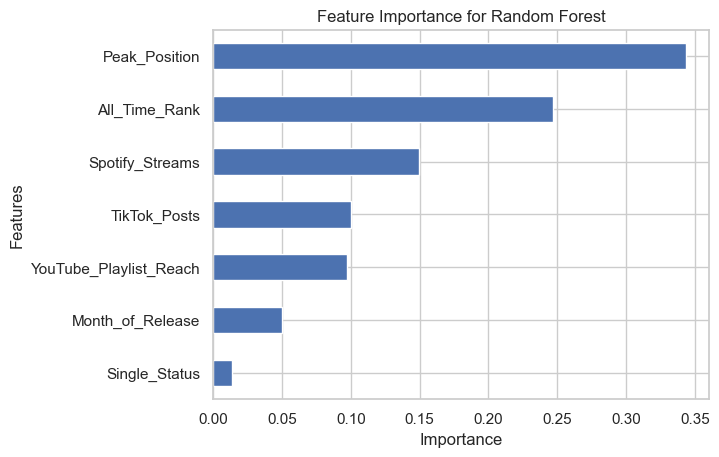

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc
)
from sklearn.metrics import ConfusionMatrixDisplay
import warnings; warnings.filterwarnings('ignore')
np.random.seed(42)
df_raw = pd.read_csv('fixed_project_data.csv')
# Single Status: derived from Album Name
df_raw['Single_Status'] = (
    df_raw['Album Name'].str.lower()
    .str.contains('single').astype(int)
)
# Collapse to one row per track
track_df = df_raw.groupby('Track').agg(
    Spotify_Streams        = ('Spotify Streams',         'first'),
    YouTube_Playlist_Reach  = ('YouTube Playlist Reach', 'first'),
    TikTok_Posts           = ('TikTok Posts',           'first'),
    Single_Status          = ('Single_Status',          'first'),
    All_Time_Rank          = ('All Time Rank',          'first'),
    Release_Date           = ('Release Date',           'first'),
    Peak_Position          = ('Peak Position',          'min'),
    Max_Weeks              = ('Weeks on Chart',         'max'),
).reset_index()
track_df['Month_of_Release'] = pd.to_datetime(
    track_df['Release_Date'], errors='coerce').dt.month
model_df = track_df.dropna(subset=['Max_Weeks', 'Peak_Position']).copy()
# ── Target ──────────────────────────────────────────────
model_df['Hit_Type'] = (model_df['Max_Weeks'] >= 20).astype(int)
FEATURES = [
    'Spotify_Streams',
    'YouTube_Playlist_Reach',
    'TikTok_Posts',
    'Single_Status',
    'All_Time_Rank',
    'Month_of_Release',
    'Peak_Position',
]
model_df[FEATURES] = model_df[FEATURES].fillna(model_df[FEATURES].median())
X = model_df[FEATURES]
y = model_df['Hit_Type']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
# ═══════════════════════════════════════════════════════
# 2.  MODEL
# ═══════════════════════════════════════════════════════
rf = RandomForestClassifier(
    n_estimators      = 300,
    max_depth         = 10,
    min_samples_split = 8,
    class_weight      = 'balanced',
    random_state      = 42,
    n_jobs            = -1,
)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

feature_importances = pd.Series(rf.feature_importances_, index=X_train.columns)
feature_importances.nlargest(7).plot(kind='barh')
plt.title("Feature Importance for Random Forest")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.gca().invert_yaxis()
print(classification_report(y_test, y_pred))

**Q1 Interpretation:** This visualization shows a very weak positive relationship between a song's TikTok likes and its all-time rank on the Billboard Top 100. For the majority of the Tiktok Likes range, it has no correlation to the song's rank; however, at the very high levels of TikTok likes, there is a strong positive relationship. Nonetheless, for most of the songs, its TikTok likes vary widely without having an impact on its ranking. The positive relationship is only present at the extreme number of TikTok likes.

### Q2: Which social media platform has the strongest correlation to Spotify streams?

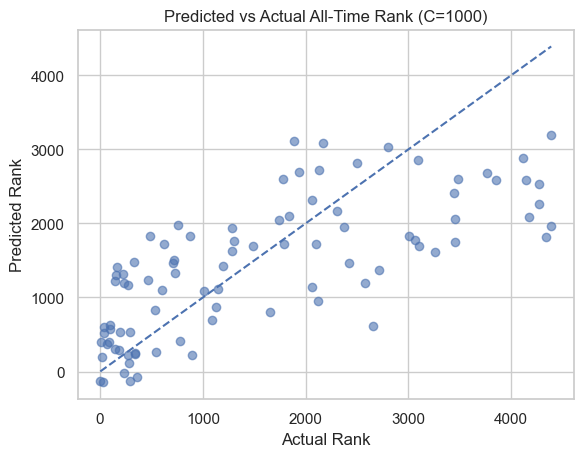

C = 1000
RMSE:  958.1787
R^2:  0.5162


In [10]:
# ── FIGURE/TABLE for Q2 ──
# social media columns
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.metrics import mean_squared_error, r2_score
np.random.seed(42)
df = pd.read_csv('fixed_project_data.csv')
df['Single_Status'] = (
    df['Album Name'].str.lower()
    .str.contains('single').astype(int)
)
# Combine duplicate appearances
track_df = df.groupby(['Track']).agg(
    Single_Status          = ('Single_Status',          'first'),
    Release_Date           = ('Release Date',           'first'),
    Weeks_On_Chart              = ('Weeks on Chart',         'max'),
    Spotify_Popularity = ('Spotify Popularity', 'first'),
    YouTube_Likes = ('YouTube Likes', 'first'),
    Billboard_Rank = ('Billboard Rank', 'min'),
    TikTok_Likes = ('TikTok Likes', 'first'),
    All_Time_Rank          = ('All Time Rank',          'first')
).reset_index()
track_df['Month_of_Release'] = pd.to_datetime(
    track_df['Release_Date'], errors='coerce').dt.month
model_df = track_df.dropna(subset=['Weeks_On_Chart']).copy()

features = ['YouTube_Likes', 'TikTok_Likes', 'Spotify_Popularity', 'Weeks_On_Chart', 'Single_Status', 'Billboard_Rank', 'Month_of_Release']
model_df[features] = model_df[features].fillna(model_df[features].median())
X = model_df[features]
y = model_df['All_Time_Rank']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
svm = SVR(kernel='rbf', C=1000)
svm.fit(X_train_scaled, y_train)
y_pred = svm.predict(X_test_scaled)
residuals = y_test - y_pred
plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Rank")
plt.ylabel("Predicted Rank")
plt.title("Predicted vs Actual All-Time Rank (C=1000)")

plt.show()
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"C = 1000")
print(f"RMSE: {rmse: .4f}")
print(f"R^2: {r2: .4f}")

**Q2 Interpretation:** Youtube is the platform with the strongest correlation with a song's Spotify streams. However, the correlation is still weak because the correlation coefficients for YouTube likes and views are around 0.5.